# Problem 1 — RNN, LSTM and GRU (chosen configuration: h=64, d=64, seeds 17/42/2026)

The assignment uses recurrent hidden size $h=64$, Transformer width $d=64$, and seeds $(17,42,2026)$; $d=64$ is divisible by the 1, 4, and 8 attention-head counts used in Problem 2. Run all cells in order. Existing rows in `results.csv` belong to older configurations unless they match the current seeds and expected keys; missing current rows are trained and appended automatically.

In [3]:
# --- Reproducibility, paths, and data-generation configuration ---
from pathlib import Path

# Start from the launch directory, but fall back one level when Jupyter opens inside problem1/.
ROOT = Path.cwd()
if not (ROOT / 'requirements.txt').exists() and (ROOT.parent / 'requirements.txt').exists(): ROOT = ROOT.parent
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Keep Problem 1 figures in a dedicated output directory and create it on first use.
P1_DIR = ROOT / 'problem1'
P1_FIGURES = P1_DIR / 'figures'
P1_FIGURES.mkdir(parents=True, exist_ok=True)

# Reproducibility
SEEDS = (17, 42, 2026)

# Primary recurrent-model configuration
P1_HIDDEN_SIZE = 64

# Training budget
P1_HAR_EPOCHS = 20
P1_ADDING_EPOCHS = 20
P1_ABLATION_EPOCHS = 20
P1_GRADIENT_EPOCHS = 20
P1_SWEEP_EPOCHS = 20

# Adding problem
P1_ADDING_LENGTHS = (50, 100, 200, 400)
P1_GRADIENT_SEQ_LEN = 100
P1_ABLATION_SEQ_LEN = 200
P1_ADDING_TRAIN_SIZE = 10_000
P1_ADDING_VAL_SIZE = 1_000
P1_ADDING_TEST_SIZE = 1_000
P1_ADDING_TRAIN_SEED = 0
P1_ADDING_VAL_SEED = 1
P1_ADDING_TEST_SEED = 2
P1_SOLVED_MSE = 0.05
P1_BASELINE_MSE = 0.167

# HAR
P1_HAR_SEQ_LEN = 128
P1_HAR_CHANNELS = 9
P1_HAR_CLASSES = 6
P1_VAL_SUBJECTS = 4

# Optimisation
P1_LR = 1e-3
P1_BATCH_SIZE = 128

# Hidden-size experiment
P1_HIDDEN_SWEEP = (16, 32, 64, 128)

# Individual ablation
P1_ABLATION = "forget_bias"
if P1_ABLATION != 'forget_bias':
    raise ValueError("P1_ABLATION must select the forget-bias 0 versus 1 comparison")
ABLATION_MODELS = (
    "LSTM-forget-bias-0",
    "LSTM-forget-bias-1",
)

# Prefer CUDA when available; all code also supports CPU execution.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# Append all experiment rows to the shared, fixed-schema results table.
RESULTS = ROOT / 'results.csv'
print('device:', DEVICE)
print(f'chosen configuration: h={P1_HIDDEN_SIZE}, d=64, seeds={SEEDS}; ablation={P1_ABLATION}')
print('results:', RESULTS)
print ('ROOT:', ROOT)
print ('Path:', Path("."))
print ('Parent', ROOT.parent)
print ('Path.cwd():', Path.cwd())
print("Files here:", [p.name for p in ROOT.parent.iterdir()])
print("Files here:", [p.name for p in Path.cwd().iterdir()])

print("\nDoes requirements.txt exist?", (Path.cwd() / "requirements.txt").exists())
print("Does problem1 exist?", (Path.cwd() / "problem1").exists())
print("Does problem2 exist?", (Path.cwd() / "problem2").exists())

print('P1_DIR:', P1_DIR)

device: cuda
chosen configuration: h=64, d=64, seeds=(17, 42, 2026); ablation=forget_bias
results: /content/results.csv
ROOT: /content
Path: .
Parent /
Path.cwd(): /content
Files here: ['dev', 'proc', 'bin', 'home', 'srv', 'var', 'lib', 'run', 'etc', 'tmp', 'mnt', 'boot', 'usr', 'root', 'opt', 'sys', 'media', 'sbin', 'lib64', 'kaggle', 'content', '.dockerenv', 'backend-container', 'tools', 'datalab', 'python-apt', 'python-apt.tar.xz', 'sbin.usr-is-merged', 'bin.usr-is-merged', 'lib.usr-is-merged', 'NGC-DL-CONTAINER-LICENSE', 'cuda-keyring_1.1-1_all.deb']
Files here: ['.config', 'problem1', 'sample_data']

Does requirements.txt exist? False
Does problem1 exist? True
Does problem2 exist? False
P1_DIR: /content/problem1


In [ ]:
# Bound CPU parallelism so timing and small experiments remain predictable.
torch.set_num_threads(min(4, torch.get_num_threads()))
print('CPU threads:', torch.get_num_threads())

CPU threads: 1


In [ ]:
"""Recurrent cells, data pipelines, and experiment helpers for Assignment 2."""

from __future__ import annotations

import csv
import random
import time
import urllib.request
import zipfile
from pathlib import Path
from typing import Iterable

import numpy as np
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Every experiment writes the same 12 fields so both problems can share results.csv.
RESULT_COLUMNS = (
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats",
    "bits_per_char", "notes",
)
# The nine inertial channels form each HAR input tensor's final feature dimension.
HAR_CHANNELS = (
    "body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y",
    "body_gyro_z", "total_acc_x", "total_acc_y", "total_acc_z",
)


# Seed Python, NumPy, CPU Torch, and all CUDA devices for repeatable experiments.
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Generate the adding task as (N,T,2) values/markers and their two-value sums.
def make_adding(n: int, T: int, seed: int) -> tuple[np.ndarray, np.ndarray]:
    if n < 1 or T < 2:
        raise ValueError("n must be positive and T must be at least 2")
    rng = np.random.default_rng(seed)
    # Channel 0 contains random values; channel 1 marks exactly two values to add.
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    # Place one marker in each half to force long-range information retention.
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    # The regression target is the sum of channel-0 values at the marked positions.
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)


# Verify marker placement and recompute each adding target independently.
def test_adding_generator() -> None:
    x, y = make_adding(256, 101, 17)
    markers = x[:, :, 1]
    assert np.all(markers.sum(axis=1) == 2)
    assert np.all(markers[:, :50].sum(axis=1) == 1)
    assert np.all(markers[:, 50:].sum(axis=1) == 1)
    np.testing.assert_allclose(y, (x[:, :, 0] * markers).sum(axis=1), atol=1e-6)


# Implement one tanh RNN step for batch inputs x:(B,I) and states h:(B,H).
class MyRNNCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, bias: bool = True):
        super().__init__()
        self.input_linear = nn.Linear(input_size, hidden_size, bias=bias)
        self.hidden_linear = nn.Linear(hidden_size, hidden_size, bias=bias)

    def forward(self, x: torch.Tensor, h: torch.Tensor) -> torch.Tensor:
        # h_t = tanh(W_x x_t + b_x + W_h h_(t-1) + b_h), with shape (B,H).
        return torch.tanh(self.input_linear(x) + self.hidden_linear(h))


# Implement one LSTM step with four gates over (B,H) hidden and cell states.
class MyLSTMCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, bias: bool = True):
        super().__init__()
        # One packed projection computes input, forget, candidate, and output preactivations.
        self.input_linear = nn.Linear(input_size, 4 * hidden_size, bias=bias)
        self.hidden_linear = nn.Linear(hidden_size, 4 * hidden_size, bias=bias)

    def forward(
        self, x: torch.Tensor, state: tuple[torch.Tensor, torch.Tensor]
    ) -> tuple[torch.Tensor, torch.Tensor]:
        h, c = state
        # Split packed (B,4H) preactivations into i, f, g, o tensors of shape (B,H).
        i, f, g, o = (self.input_linear(x) + self.hidden_linear(h)).chunk(4, dim=-1)
        i, f, o = i.sigmoid(), f.sigmoid(), o.sigmoid()
        # c_t = f_t*c_(t-1) + i_t*tanh(g_t); h_t = o_t*tanh(c_t).
        c_next = f * c + i * g.tanh()
        return o * c_next.tanh(), c_next


# Implement one GRU step with reset, update, and candidate tensors of shape (B,H).
class MyGRUCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int, bias: bool = True):
        super().__init__()
        self.input_linear = nn.Linear(input_size, 3 * hidden_size, bias=bias)
        self.hidden_linear = nn.Linear(hidden_size, 3 * hidden_size, bias=bias)

    def forward(self, x: torch.Tensor, h: torch.Tensor) -> torch.Tensor:
        # Split each packed (B,3H) projection in PyTorch's reset/update/new gate order.
        x_r, x_z, x_n = self.input_linear(x).chunk(3, dim=-1)
        h_r, h_z, h_n = self.hidden_linear(h).chunk(3, dim=-1)
        reset = (x_r + h_r).sigmoid()
        update = (x_z + h_z).sigmoid()
        candidate = (x_n + reset * h_n).tanh()
        # Interpolate between the new candidate and previous hidden state via update z_t.
        return candidate + update * (h - candidate)


# Copy a built-in RNN's packed parameters into the custom cell for numerical verification.
def copy_rnn_weights(source: nn.RNN, target: MyRNNCell) -> None:
    with torch.no_grad():
        target.input_linear.weight.copy_(source.weight_ih_l0)
        target.hidden_linear.weight.copy_(source.weight_hh_l0)
        target.input_linear.bias.copy_(source.bias_ih_l0)
        target.hidden_linear.bias.copy_(source.bias_hh_l0)


# Copy a built-in LSTM's matching i/f/g/o packed parameters into the custom cell.
def copy_lstm_weights(source: nn.LSTM, target: MyLSTMCell) -> None:
    with torch.no_grad():
        target.input_linear.weight.copy_(source.weight_ih_l0)
        target.hidden_linear.weight.copy_(source.weight_hh_l0)
        target.input_linear.bias.copy_(source.bias_ih_l0)
        target.hidden_linear.bias.copy_(source.bias_hh_l0)


# Copy a built-in GRU's matching r/z/n packed parameters into the custom cell.
def copy_gru_weights(source: nn.GRU, target: MyGRUCell) -> None:
    with torch.no_grad():
        target.input_linear.weight.copy_(source.weight_ih_l0)
        target.hidden_linear.weight.copy_(source.weight_hh_l0)
        target.input_linear.bias.copy_(source.bias_ih_l0)
        target.hidden_linear.bias.copy_(source.bias_hh_l0)


# Unroll each custom cell and compare it numerically with the corresponding PyTorch layer.
def test_cells_match_torch() -> None:
    torch.manual_seed(3)
    batch, steps, input_size, hidden_size = 5, 7, P1_HAR_CHANNELS, 11
    x = torch.randn(batch, steps, input_size)
    h0 = torch.randn(1, batch, hidden_size)

    # Built-ins are reference implementations here, not the custom-cell implementation itself.
    library_rnn = nn.RNN(input_size, hidden_size, batch_first=True)
    custom_rnn = MyRNNCell(input_size, hidden_size)
    copy_rnn_weights(library_rnn, custom_rnn)
    h = h0[0]
    outputs = []
    for t in range(steps):
        h = custom_rnn(x[:, t], h)
        outputs.append(h)
    torch.testing.assert_close(torch.stack(outputs, dim=1), library_rnn(x, h0)[0], atol=1e-5, rtol=1e-5)

    library_lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
    custom_lstm = MyLSTMCell(input_size, hidden_size)
    copy_lstm_weights(library_lstm, custom_lstm)
    h, c = h0[0], torch.randn(batch, hidden_size)
    c0 = c.clone()
    outputs = []
    for t in range(steps):
        h, c = custom_lstm(x[:, t], (h, c))
        outputs.append(h)
    torch.testing.assert_close(torch.stack(outputs, dim=1), library_lstm(x, (h0, c0.unsqueeze(0)))[0], atol=1e-5, rtol=1e-5)

    library_gru = nn.GRU(input_size, hidden_size, batch_first=True)
    custom_gru = MyGRUCell(input_size, hidden_size)
    copy_gru_weights(library_gru, custom_gru)
    h = h0[0]
    outputs = []
    for t in range(steps):
        h = custom_gru(x[:, t], h)
        outputs.append(h)
    torch.testing.assert_close(torch.stack(outputs, dim=1), library_gru(x, h0)[0], atol=1e-5, rtol=1e-5)


# Derive one-bias recurrent-cell parameter counts from input width I and hidden width H.
def hand_parameter_counts(
    input_size: int = P1_HAR_CHANNELS, hidden_size: int = P1_HIDDEN_SIZE
) -> dict[str, int]:
    return {
        "RNN": hidden_size * (input_size + hidden_size + 1),
        "LSTM": 4 * hidden_size * (input_size + hidden_size + 1),
        "GRU": 3 * hidden_size * (input_size + hidden_size + 1),
    }


# Read one whitespace-delimited HAR signal or label matrix as float32.
def _read_matrix(path: Path) -> np.ndarray:
    return np.loadtxt(path, dtype=np.float32)


# Download if needed, split HAR by subject, and normalize all sets from training subjects only.
def load_har(root: str | Path, seed: int = SEEDS[0]) -> dict[str, np.ndarray]:
    root = Path(root)
    dataset_dir = root / "UCI HAR Dataset"
    if not dataset_dir.exists():
        root.mkdir(parents=True, exist_ok=True)
        archive = root / "har.zip"
        url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
        urllib.request.urlretrieve(url, archive)
        with zipfile.ZipFile(archive) as archive_file:
            archive_file.extractall(root)
        nested = root / "UCI HAR Dataset.zip"
        if nested.exists():
            with zipfile.ZipFile(nested) as archive_file:
                archive_file.extractall(root)

    # Stack HAR channels into (N,T,C), retain subjects, and zero-index labels.
    def split(part: str) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        folder = dataset_dir / part
        signal_dir = folder / "Inertial Signals"
        signals = [_read_matrix(signal_dir / f"{name}_{part}.txt") for name in HAR_CHANNELS]
        x = np.stack(signals, axis=-1)
        if x.shape[1:] != (P1_HAR_SEQ_LEN, P1_HAR_CHANNELS):
            raise ValueError(f'Unexpected HAR input shape: {x.shape}')
        y = _read_matrix(folder / f"y_{part}.txt").astype(np.int64) - 1
        subjects = _read_matrix(folder / f"subject_{part}.txt").astype(np.int64)
        return x, y, subjects

    x_train, y_train, subject_train = split("train")
    x_test, y_test, _ = split("test")
    subjects = np.unique(subject_train)
    # Hold out complete people so windows from one subject never cross train/validation.
    val_subjects = np.random.default_rng(seed).choice(
        subjects, P1_VAL_SUBJECTS, replace=False
    )
    val_mask = np.isin(subject_train, val_subjects)
    train_mask = ~val_mask
    # Compute (1,1,9) channel statistics only on training subjects for broadcast normalization.
    mean = x_train[train_mask].mean(axis=(0, 1), keepdims=True)
    std = x_train[train_mask].std(axis=(0, 1), keepdims=True)
    std[std == 0] = 1
    return {
        "x_train": ((x_train[train_mask] - mean) / std).astype(np.float32),
        "y_train": y_train[train_mask],
        "x_val": ((x_train[val_mask] - mean) / std).astype(np.float32),
        "y_val": y_train[val_mask],
        "x_test": ((x_test - mean) / std).astype(np.float32),
        "y_test": y_test,
        "val_subjects": val_subjects,
    }


# Wrap a built-in recurrent sequence layer and classify from its final (B,H) output.
class SequenceClassifier(nn.Module):
    def __init__(
        self, kind: str, input_size: int = P1_HAR_CHANNELS,
        hidden_size: int = P1_HIDDEN_SIZE, classes: int = P1_HAR_CLASSES,
    ):
        super().__init__()
        # Built-ins provide efficient full-sequence training after custom equations are verified above.
        recurrent = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        if kind not in recurrent:
            raise ValueError(f"Unknown recurrent model: {kind}")
        self.kind = kind
        self.rnn = recurrent[kind](input_size, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        sequence, _ = self.rnn(x)
        return self.output(sequence[:, -1])


# Wrap a recurrent layer for scalar adding-task regression from the final hidden output.
class AddingRegressor(nn.Module):
    def __init__(self, kind: str, hidden_size: int, forget_bias: float = 1.0):
        super().__init__()
        recurrent = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}
        self.kind = kind
        self.rnn = recurrent[kind](2, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)
        if kind == "LSTM":
            # Set the packed forget-gate bias explicitly for the selected ablation.
            with torch.no_grad():
                self.rnn.bias_ih_l0[hidden_size:2 * hidden_size].fill_(forget_bias)
                self.rnn.bias_hh_l0[hidden_size:2 * hidden_size].zero_()

    def forward(
        self, x: torch.Tensor, return_states: bool = False
    ) -> torch.Tensor | tuple[torch.Tensor, torch.Tensor]:
        sequence, _ = self.rnn(x)
        prediction = self.output(sequence[:, -1]).squeeze(-1)
        return (prediction, sequence) if return_states else prediction


# Train minibatches with backpropagation and restore the lowest-validation-loss checkpoint.
def train_model(
    model: nn.Module,
    train_x: np.ndarray,
    train_y: np.ndarray,
    val_x: np.ndarray,
    val_y: np.ndarray,
    *,
    task: str,
    epochs: int = 20,
    batch_size: int = P1_BATCH_SIZE,
    lr: float = P1_LR,
    device: str | torch.device = "cpu",
    clip_norm: float | None = None,
) -> tuple[nn.Module, list[float], float]:
    device = torch.device(device)
    model = model.to(device)
    # DataLoader shuffles training examples into minibatches; validation stays as one fixed tensor.
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_x), torch.from_numpy(train_y)),
        batch_size=batch_size, shuffle=True,
    )
    val_inputs = torch.from_numpy(val_x).to(device)
    val_targets = torch.from_numpy(val_y).to(device)
    loss_fn = nn.CrossEntropyLoss() if task == "classification" else nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_loss = float("inf")
    best_state = None
    curve: list[float] = []
    epoch_seconds = []
    for _ in range(epochs):
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        started = time.perf_counter()
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            # Backpropagate each minibatch, optionally clip the global norm, then update parameters.
            loss.backward()
            if clip_norm is not None:
                nn.utils.clip_grad_norm_(model.parameters(), clip_norm)
            optimizer.step()
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        epoch_seconds.append(time.perf_counter() - started)
        model.eval()
        with torch.no_grad():
            val_loss = float(loss_fn(model(val_inputs), val_targets).item())
        curve.append(val_loss)
        # Clone the best state onto CPU so checkpoint choice depends only on validation loss.
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
    if best_state is None:
        raise RuntimeError("Training completed without a validation checkpoint")
    model.load_state_dict(best_state)
    return model, curve, float(np.mean(epoch_seconds))


# Compute accuracy, macro-F1, and a fixed 6x6 confusion matrix on held-out HAR data.
def evaluate_classifier(
    model: nn.Module, x: np.ndarray, y: np.ndarray, device: str | torch.device = "cpu"
) -> tuple[float, float, np.ndarray]:
    model.eval()
    with torch.no_grad():
        pred = model(torch.from_numpy(x).to(device)).argmax(dim=1).cpu().numpy()
    return (
        float(accuracy_score(y, pred)),
        float(f1_score(y, pred, average="macro", zero_division=0)),
        confusion_matrix(y, pred, labels=np.arange(P1_HAR_CLASSES)),
    )


# Append one row using the shared result schema, filling irrelevant task fields with blanks.
def append_result(path: str | Path, row: dict[str, object]) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    write_header = not path.exists()
    with path.open("a", newline="", encoding="utf-8") as output_file:
        writer = csv.DictWriter(output_file, fieldnames=RESULT_COLUMNS)
        if write_header:
            writer.writeheader()
        writer.writerow({column: row.get(column, "") for column in RESULT_COLUMNS})


# Manually unroll packed recurrent weights and measure mean ||dL/dh_t|| at every step.
def gradient_norms(
    model: AddingRegressor, x: np.ndarray, y: np.ndarray, device: str = "cpu"
) -> np.ndarray:
    model.eval()
    model.zero_grad(set_to_none=True)
    xb = torch.from_numpy(x).to(device)
    target = torch.from_numpy(y).to(device)
    batch, steps, _ = xb.shape
    hidden_size = model.rnn.hidden_size
    h = xb.new_zeros(batch, hidden_size)
    c = xb.new_zeros(batch, hidden_size) if model.kind == "LSTM" else None
    retained_hidden = []
    # Recreate the recurrence from packed PyTorch weights so each intermediate h_t is exposed.
    for step in range(steps):
        input_values = nn.functional.linear(xb[:, step], model.rnn.weight_ih_l0, model.rnn.bias_ih_l0)
        hidden_values = nn.functional.linear(h, model.rnn.weight_hh_l0, model.rnn.bias_hh_l0)
        if model.kind == "RNN":
            h = torch.tanh(input_values + hidden_values)
        elif model.kind == "LSTM":
            i, f, g, o = (input_values + hidden_values).chunk(4, dim=-1)
            c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
            h = torch.sigmoid(o) * torch.tanh(c)
        elif model.kind == "GRU":
            i_r, i_z, i_n = input_values.chunk(3, dim=-1)
            h_r, h_z, h_n = hidden_values.chunk(3, dim=-1)
            reset = torch.sigmoid(i_r + h_r)
            update = torch.sigmoid(i_z + h_z)
            candidate = torch.tanh(i_n + reset * h_n)
            h = (1 - update) * candidate + update * h
        else:
            raise ValueError(f"Unknown recurrent model: {model.kind}")
        # Non-leaf hidden tensors need retain_grad() before the final backward pass.
        h.retain_grad()
        retained_hidden.append(h)
    prediction = model.output(h).squeeze(-1)
    nn.functional.mse_loss(prediction, target).backward()
    if any(hidden.grad is None for hidden in retained_hidden):
        raise RuntimeError("A recurrent hidden-state gradient was not retained")
    return np.asarray([
        hidden.grad.norm(dim=-1).mean().detach().cpu().item()
        for hidden in retained_hidden
    ])


# Run the complete model/length/seed Cartesian grid for adding-task regression.
def run_adding_experiment(
    output_csv: str | Path = "results.csv", *, device: str = "cpu",
    epochs: int = P1_ADDING_EPOCHS, hidden_size: int = P1_HIDDEN_SIZE,
    batch_size: int = P1_BATCH_SIZE, seeds: Iterable[int] = SEEDS,
) -> list[dict[str, object]]:
    rows = []
    for length in P1_ADDING_LENGTHS:
        train_x, train_y = make_adding(
            P1_ADDING_TRAIN_SIZE, length, P1_ADDING_TRAIN_SEED
        )
        val_x, val_y = make_adding(
            P1_ADDING_VAL_SIZE, length, P1_ADDING_VAL_SEED
        )
        test_x, test_y = make_adding(
            P1_ADDING_TEST_SIZE, length, P1_ADDING_TEST_SEED
        )
        for kind in ("RNN", "LSTM", "GRU"):
            for seed in seeds:
                set_seed(seed)
                model = AddingRegressor(kind, hidden_size)
                model, curve, seconds = train_model(
                    model, train_x, train_y, val_x, val_y, task="regression",
                    epochs=epochs, batch_size=batch_size, device=device,
                )
                model.eval()
                with torch.no_grad():
                    mse = float(nn.functional.mse_loss(
                        model(torch.from_numpy(test_x).to(device)),
                        torch.from_numpy(test_y).to(device),
                    ).item())
                row = {
                    "problem": "P1-adding", "model": kind, "seed": seed,
                    "seq_len": length, "test_mse": mse,
                    "params": sum(parameter.numel() for parameter in model.parameters()),
                    "sec_per_epoch": seconds,
                    "notes": f"hidden_size={hidden_size};epochs={epochs};solved={mse < P1_SOLVED_MSE};baseline_mse={P1_BASELINE_MSE};best_val_mse={min(curve):.6f}",
                }
                append_result(output_csv, row)
                rows.append(row)
    return rows


# Save a bar chart of training-subject activity counts to expose class imbalance.
def plot_har_class_balance(data: dict[str, np.ndarray], path: str | Path) -> None:
    labels = ("walking", "upstairs", "downstairs", "sitting", "standing", "laying")
    counts = np.bincount(data["y_train"], minlength=P1_HAR_CLASSES)
    figure, axis = plt.subplots(figsize=(8, 4))
    axis.bar(labels, counts)
    axis.set_ylabel("Training windows")
    axis.set_title("UCI HAR training class balance")
    axis.tick_params(axis="x", rotation=20)
    figure.tight_layout()
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=160)
    plt.close(figure)


# Train and evaluate each recurrent HAR classifier across the requested seeds.
def run_har_experiment(
    data: dict[str, np.ndarray] | str | Path, output_csv: str | Path = "results.csv",
    *, device: str = "cpu", epochs: int = P1_HAR_EPOCHS, batch_size: int = P1_BATCH_SIZE,
    hidden_size: int = P1_HIDDEN_SIZE, seeds: Iterable[int] = SEEDS,
) -> list[dict[str, object]]:
    rows = []
    for kind in ("RNN", "LSTM", "GRU"):
        for seed in seeds:
            set_seed(seed)
            seed_data = load_har(data, seed=seed) if isinstance(data, (str, Path)) else data
            model = SequenceClassifier(kind, hidden_size=hidden_size)
            model, curve, seconds = train_model(
                model, seed_data["x_train"], seed_data["y_train"],
                seed_data["x_val"], seed_data["y_val"], task="classification",
                epochs=epochs, batch_size=batch_size, device=device,
            )
            accuracy, macro_f1, matrix = evaluate_classifier(
                model, seed_data["x_test"], seed_data["y_test"], device
            )
            row = {
                "problem": "P1-HAR", "model": kind, "seed": seed,
                "test_acc": accuracy, "macro_f1": macro_f1,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": seconds,
                "notes": f"hidden_size={hidden_size};epochs={epochs};best_val_loss={min(curve):.6f};confusion={matrix.tolist()}",
            }
            append_result(output_csv, row)
            rows.append(row)
    return rows


# Compare LSTM forget biases 0 and 1 at fixed T=200 under matched budgets.
def run_individual_ablation(
    output_csv: str | Path = "results.csv", *, device: str = "cpu",
    epochs: int = P1_ABLATION_EPOCHS, hidden_size: int = P1_HIDDEN_SIZE,
    batch_size: int = P1_BATCH_SIZE, seeds: Iterable[int] = SEEDS,
) -> list[dict[str, object]]:
    if P1_ABLATION != "forget_bias":
        raise ValueError("Only the selected forget-bias ablation is configured")
    length = P1_ABLATION_SEQ_LEN
    train_x, train_y = make_adding(
        P1_ADDING_TRAIN_SIZE, length, P1_ADDING_TRAIN_SEED
    )
    val_x, val_y = make_adding(
        P1_ADDING_VAL_SIZE, length, P1_ADDING_VAL_SEED
    )
    test_x, test_y = make_adding(
        P1_ADDING_TEST_SIZE, length, P1_ADDING_TEST_SEED
    )
    variants = tuple(zip(ABLATION_MODELS, (0.0, 1.0)))
    rows = []
    for label, forget_bias in variants:
        for seed in seeds:
            set_seed(seed)
            model = AddingRegressor("LSTM", hidden_size, forget_bias=forget_bias)
            model, curve, seconds = train_model(
                model, train_x, train_y, val_x, val_y, task="regression",
                epochs=epochs, batch_size=batch_size, device=device,
            )
            model.eval()
            with torch.no_grad():
                mse = float(nn.functional.mse_loss(
                    model(torch.from_numpy(test_x).to(device)),
                    torch.from_numpy(test_y).to(device),
                ).item())
            row = {
                "problem": "P1-ablation", "model": label, "seed": seed,
                "seq_len": length, "test_mse": mse,
                "params": sum(parameter.numel() for parameter in model.parameters()),
                "sec_per_epoch": seconds,
                "notes": f"hidden_size={hidden_size};epochs={epochs};best_val_mse={min(curve):.6f};forget_bias={forget_bias}",
            }
            append_result(output_csv, row)
            rows.append(row)
    return rows

In [ ]:
# --- Cheap generator, custom-cell, parameter-count, and BPTT assertions ---

# Validate adding-task construction and all three custom recurrences against PyTorch.
test_adding_generator()
test_cells_match_torch()

# Recompute the assignment's one-bias formulas for the chosen width.
counts = hand_parameter_counts(P1_HAR_CHANNELS, P1_HIDDEN_SIZE)
assert counts == {'RNN': 4736, 'LSTM': 18944, 'GRU': 14208}

# Confirm manual BPTT returns finite per-step gradients, including pre-final states.
probe_x, probe_y = make_adding(4, 8, 23)
for kind in ('RNN', 'LSTM', 'GRU'):
    norms = gradient_norms(AddingRegressor(kind, 6), probe_x, probe_y)
    assert norms.shape == (8,)
    assert np.isfinite(norms).all()
    assert np.any(norms[:-1] > 0), f'{kind} has no pre-final hidden gradient'

# PyTorch stores separate input/recurrent biases, adding H, 4H, or 3H parameters.
pytorch_counts = {
    'RNN': counts['RNN'] + P1_HIDDEN_SIZE,
    'LSTM': counts['LSTM'] + 4 * P1_HIDDEN_SIZE,
    'GRU': counts['GRU'] + 3 * P1_HIDDEN_SIZE,
}
# Add the shared h-to-6 classifier weight matrix and six output biases.
classifier_counts = {
    kind: count + P1_HIDDEN_SIZE * P1_HAR_CLASSES + P1_HAR_CLASSES
    for kind, count in pytorch_counts.items()
}
assert pytorch_counts == {'RNN': 4800, 'LSTM': 19200, 'GRU': 14400}
assert classifier_counts == {'RNN': 5190, 'LSTM': 19590, 'GRU': 14790}
print(f'custom h={P1_HIDDEN_SIZE} counts:', counts)
print(f'PyTorch two-bias h={P1_HIDDEN_SIZE} counts:', pytorch_counts)
print(f'HAR classifier h={P1_HIDDEN_SIZE} counts:', classifier_counts)
print('custom-cell and recurrent-gradient tests passed')

custom h=64 counts: {'RNN': 4736, 'LSTM': 18944, 'GRU': 14208}
PyTorch two-bias h=64 counts: {'RNN': 4800, 'LSTM': 19200, 'GRU': 14400}
HAR classifier h=64 counts: {'RNN': 5190, 'LSTM': 19590, 'GRU': 14790}
custom-cell and recurrent-gradient tests passed


## Required resumable experiments

Run All executes every missing HAR, adding-task, and selected-ablation experiment before reporting results. Rows are appended after each run so interrupted sessions can resume, and strict inventory checks reject missing or duplicate model/seed/length combinations before aggregation. Each HAR seed is an independently trained run with its own subject-wise validation split; normalization is fitted only on that run's training subjects, and its checkpoint is selected solely by validation loss. The official test set is evaluated afterward for reporting and is not used to select checkpoints, models, or hyperparameters.

## Required resumable experiments

Run All runs or resumes every required HAR, adding-task, and selected-ablation experiment before reporting results. Rows are appended after each run so interrupted sessions can resume, and strict inventory checks reject missing or duplicate model/seed/length combinations before aggregation. Each HAR seed is independently trained with its own subject-wise validation split; normalization is fitted only on that run's training subjects, and checkpoint selection uses validation loss only. The official test set is evaluated afterward for reporting.

In [ ]:
# --- Resumable experiment runners and strict result validation ---

# Check whether a row already exists for the exact task/model/seed/length/parameter configuration.
def result_exists(problem, model, seed, seq_len=None, expected_params=None):
    if not RESULTS.exists():
        return False
    existing = pd.read_csv(RESULTS)
    selected = existing[
        existing.problem.eq(problem)
        & existing.model.eq(model)
        & existing.seed.eq(seed)
    ]
    selected = selected[selected.seq_len.isna()] if seq_len is None else selected[selected.seq_len.eq(seq_len)]
    # Parameter filtering excludes stale rows from older hidden-size configurations.
    if expected_params is not None:
        selected = selected[selected.params.eq(expected_params)]
    return not selected.empty


# Require the exact model x seed x optional-length Cartesian grid with no duplicates.
def validate_result_grid(problem, models, seeds, lengths=None, expected_params=None):
    if not RESULTS.exists():
        raise AssertionError(f'{RESULTS} does not exist')
    results = pd.read_csv(RESULTS)
    selected = results[
        results.problem.eq(problem)
        & results.model.isin(models)
        & results.seed.isin(seeds)
    ].copy()
    # Keep only rows whose parameter counts identify the current configuration.
    if expected_params is not None:
        selected = selected[
            selected.apply(
                lambda row: row['params'] == expected_params[row['model']], axis=1
            )
        ]
    key_columns = ['model', 'seed']
    selected['seed'] = selected['seed'].astype(int)
    if lengths is None:
        selected = selected[selected.seq_len.isna()]
        expected = {(model, seed) for model in models for seed in seeds}
    else:
        selected = selected[selected.seq_len.isin(lengths)]
        selected['seq_len'] = selected['seq_len'].astype(int)
        key_columns.append('seq_len')
        expected = {
            (model, seed, length)
            for model in models for seed in seeds for length in lengths
        }
    duplicates = selected[selected.duplicated(key_columns, keep=False)]
    observed = set(selected[key_columns].itertuples(index=False, name=None))
    missing = expected - observed
    unexpected = observed - expected
    if not duplicates.empty or missing or unexpected:
        raise AssertionError(
            f'Invalid {problem} inventory: missing={sorted(missing)}, '
            f'unexpected={sorted(unexpected)}, duplicate_rows={len(duplicates)}'
        )
    return selected.sort_values(key_columns).reset_index(drop=True)


# Resume missing HAR model/seed runs, each with its own subject-wise validation split.
def run_har_resumable():
    rows = []
    for kind in ('RNN', 'LSTM', 'GRU'):
        expected_params = classifier_counts[kind]
        for seed in SEEDS:
            if result_exists('P1-HAR', kind, seed, expected_params=expected_params):
                continue
            set_seed(seed)
            seed_data = load_har(ROOT / 'data', seed=seed)
            model = SequenceClassifier(kind, hidden_size=P1_HIDDEN_SIZE)
            model, curve, seconds = train_model(
                model, seed_data['x_train'], seed_data['y_train'],
                seed_data['x_val'], seed_data['y_val'], task='classification',
                epochs=P1_HAR_EPOCHS, batch_size=P1_BATCH_SIZE, device=DEVICE,
            )
            accuracy, macro_f1, matrix = evaluate_classifier(
                model, seed_data['x_test'], seed_data['y_test'], DEVICE
            )
            row = {
                'problem': 'P1-HAR', 'model': kind, 'seed': seed,
                'test_acc': accuracy, 'macro_f1': macro_f1,
                'params': sum(parameter.numel() for parameter in model.parameters()),
                'sec_per_epoch': seconds,
                'notes': (
                    f'hidden_size={P1_HIDDEN_SIZE};epochs={P1_HAR_EPOCHS};'
                    f'best_val_loss={min(curve):.6f};confusion={matrix.tolist()}'
                ),
            }
            append_result(RESULTS, row)
            rows.append(row)
    return rows


# Resume the 3 models x 3 seeds x 4 lengths adding-task grid.
def run_adding_resumable():
    rows = []
    adding_params = {
        kind: sum(parameter.numel() for parameter in AddingRegressor(kind, P1_HIDDEN_SIZE).parameters())
        for kind in ('RNN', 'LSTM', 'GRU')
    }
    # Fixed data seeds make model seeds comparable at T=50,100,200,400.
    for length in P1_ADDING_LENGTHS:
        train_x, train_y = make_adding(
            P1_ADDING_TRAIN_SIZE, length, P1_ADDING_TRAIN_SEED
        )
        val_x, val_y = make_adding(
            P1_ADDING_VAL_SIZE, length, P1_ADDING_VAL_SEED
        )
        test_x, test_y = make_adding(
            P1_ADDING_TEST_SIZE, length, P1_ADDING_TEST_SEED
        )
        for kind in ('RNN', 'LSTM', 'GRU'):
            for seed in SEEDS:
                if result_exists('P1-adding', kind, seed, length, adding_params[kind]):
                    continue
                set_seed(seed)
                model = AddingRegressor(kind, P1_HIDDEN_SIZE)
                model, curve, seconds = train_model(
                    model, train_x, train_y, val_x, val_y, task='regression',
                    epochs=P1_ADDING_EPOCHS, batch_size=P1_BATCH_SIZE, device=DEVICE,
                )
                model.eval()
                with torch.no_grad():
                    mse = float(torch.nn.functional.mse_loss(
                        model(torch.from_numpy(test_x).to(DEVICE)),
                        torch.from_numpy(test_y).to(DEVICE),
                    ).item())
                row = {
                    'problem': 'P1-adding', 'model': kind, 'seed': seed,
                    'seq_len': length, 'test_mse': mse,
                    'params': sum(parameter.numel() for parameter in model.parameters()),
                    'sec_per_epoch': seconds,
                    'notes': (
                        f'hidden_size={P1_HIDDEN_SIZE};epochs={P1_ADDING_EPOCHS};'
                        f'solved={mse < P1_SOLVED_MSE};baseline_mse={P1_BASELINE_MSE};'
                        f'best_val_mse={min(curve):.6f}'
                    ),
                }
                append_result(RESULTS, row)
                rows.append(row)
    return rows


# Resume the matched forget-bias 0/1 x seed comparison at T=200.
def run_ablation_resumable():
    if P1_ABLATION != 'forget_bias':
        raise ValueError('Only the selected forget-bias ablation is configured')
    length = P1_ABLATION_SEQ_LEN
    train_x, train_y = make_adding(
        P1_ADDING_TRAIN_SIZE, length, P1_ADDING_TRAIN_SEED
    )
    val_x, val_y = make_adding(
        P1_ADDING_VAL_SIZE, length, P1_ADDING_VAL_SEED
    )
    test_x, test_y = make_adding(
        P1_ADDING_TEST_SIZE, length, P1_ADDING_TEST_SEED
    )
    forget_biases = dict(zip(ABLATION_MODELS, (0.0, 1.0)))
    expected_params = sum(
        parameter.numel() for parameter in AddingRegressor('LSTM', P1_HIDDEN_SIZE).parameters()
    )
    rows = []
    for label in ABLATION_MODELS:
        forget_bias = forget_biases[label]
        for seed in SEEDS:
            if result_exists('P1-ablation', label, seed, length, expected_params):
                continue
            set_seed(seed)
            model = AddingRegressor('LSTM', P1_HIDDEN_SIZE, forget_bias=forget_bias)
            model, curve, seconds = train_model(
                model, train_x, train_y, val_x, val_y, task='regression',
                epochs=P1_ABLATION_EPOCHS, batch_size=P1_BATCH_SIZE, device=DEVICE,
            )
            model.eval()
            with torch.no_grad():
                mse = float(torch.nn.functional.mse_loss(
                    model(torch.from_numpy(test_x).to(DEVICE)),
                    torch.from_numpy(test_y).to(DEVICE),
                ).item())
            row = {
                'problem': 'P1-ablation', 'model': label, 'seed': seed,
                'seq_len': length, 'test_mse': mse,
                'params': sum(parameter.numel() for parameter in model.parameters()),
                'sec_per_epoch': seconds,
                'notes': (
                    f'hidden_size={P1_HIDDEN_SIZE};epochs={P1_ABLATION_EPOCHS};'
                    f'best_val_mse={min(curve):.6f};forget_bias={forget_bias}'
                ),
            }
            append_result(RESULTS, row)
            rows.append(row)
    return rows

New runs this execution: HAR=9, adding=36, ablation=6
Validated result totals: HAR=9, adding=36, ablation=6


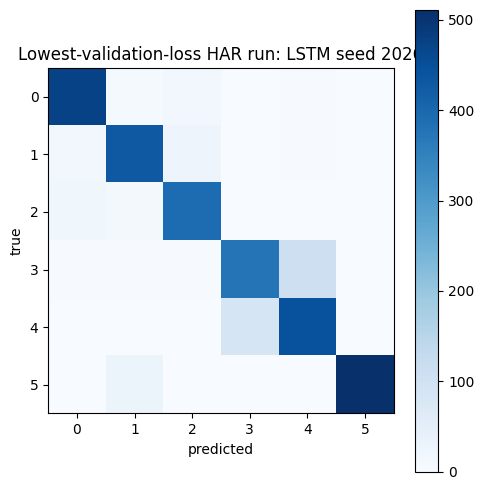

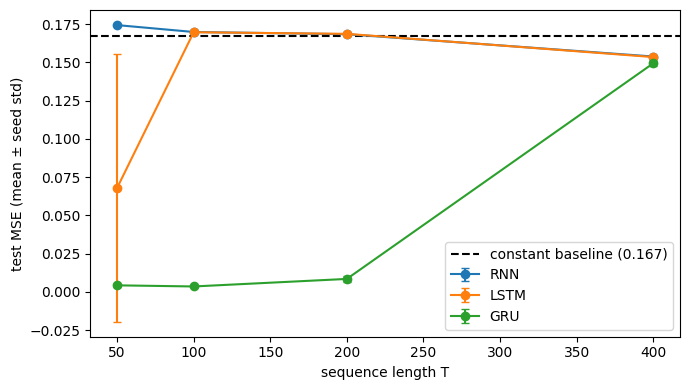

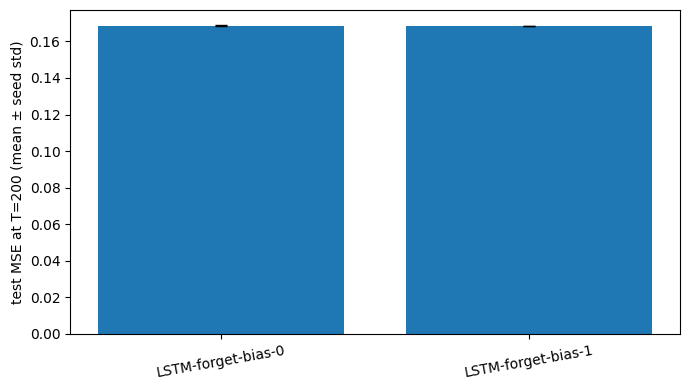

HAR test metrics across independent runs (mean ± std):
       test_acc            macro_f1             params      sec_per_epoch  \
           mean       std      mean       std     mean  std          mean   
model                                                                       
GRU    0.895261  0.003416  0.895243  0.003300  14790.0  0.0      0.143809   
LSTM   0.891076  0.004114  0.890660  0.004721  19590.0  0.0      0.161062   
RNN    0.771406  0.034052  0.760269  0.042378   5190.0  0.0      0.158088   

                 
            std  
model            
GRU    0.001922  
LSTM   0.015368  
RNN    0.036129  
Adding test MSE (mean ± std):
                   mean       std
model seq_len                    
GRU   50       0.004205  0.001026
      100      0.003469  0.000326
      200      0.008395  0.002104
      400      0.149342  0.001837
LSTM  50       0.067863  0.087542
      100      0.169670  0.000168
      200      0.168633  0.000066
      400      0.153446  0.000073
RNN 

In [ ]:
# --- Execute, validate, summarize, and plot the main experiments ---

# Build the first-seed split only for the class-balance figure.
data = load_har(ROOT / 'data', seed=SEEDS[0])
plot_har_class_balance(data, P1_FIGURES / 'har_class_balance.png')

# Each runner skips exact configuration keys already persisted in results.csv.
har_new_rows = run_har_resumable()
adding_new_rows = run_adding_resumable()
ablation_new_rows = run_ablation_resumable()

# Reconstruct current parameter signatures, then require every expected Cartesian-grid row.
models = ('RNN', 'LSTM', 'GRU')
adding_params = {
    kind: sum(parameter.numel() for parameter in AddingRegressor(kind, P1_HIDDEN_SIZE).parameters())
    for kind in models
}
ablation_params = {model: adding_params['LSTM'] for model in ABLATION_MODELS}
har = validate_result_grid('P1-HAR', models, SEEDS, expected_params=classifier_counts)
adding = validate_result_grid(
    'P1-adding', models, SEEDS, P1_ADDING_LENGTHS, expected_params=adding_params
 )
ablation = validate_result_grid(
    'P1-ablation', ABLATION_MODELS, SEEDS, (P1_ABLATION_SEQ_LEN,), expected_params=ablation_params
 )

print(
    'New runs this execution:',
    f'HAR={len(har_new_rows)}, adding={len(adding_new_rows)}, ablation={len(ablation_new_rows)}',
)
print(
    'Validated result totals:',
    f'HAR={len(har)}, adding={len(adding)}, ablation={len(ablation)}',
)

# Plot the confusion matrix from the run selected by lowest validation loss, not test score.
import ast
lowest_val_har = min(
    har.to_dict('records'),
    key=lambda row: float(row['notes'].split('best_val_loss=')[1].split(';')[0]),
)
matrix = ast.literal_eval(lowest_val_har['notes'].split('confusion=')[1])
plt.figure(figsize=(5, 5)); plt.imshow(matrix, cmap='Blues'); plt.colorbar()
plt.title(f"Lowest-validation-loss HAR run: {lowest_val_har['model']} seed {lowest_val_har['seed']}")
plt.xlabel('predicted'); plt.ylabel('true'); plt.tight_layout()
plt.savefig(P1_FIGURES / 'lowest_validation_loss_har_confusion.png', dpi=160); plt.show()

# Aggregate over seeds and use seed standard deviation as each MSE error bar.
adding_summary = adding.groupby(['model', 'seq_len']).test_mse.agg(['mean', 'std'])
plt.figure(figsize=(7, 4))
for model_name in models:
    summary = adding_summary.loc[model_name].sort_index()
    plt.errorbar(
        summary.index, summary['mean'], yerr=summary['std'], marker='o', capsize=3,
        label=model_name,
    )
plt.axhline(
    P1_BASELINE_MSE, linestyle='--', color='black',
    label=f'constant baseline ({P1_BASELINE_MSE})',
)
plt.xlabel('sequence length T'); plt.ylabel('test MSE (mean ± seed std)')
plt.legend(); plt.tight_layout()
plt.savefig(P1_FIGURES / 'adding_mse_vs_T.png', dpi=160); plt.show()

# Compare the two matched forget-bias variants with seed-standard-deviation bars.
ablation_summary = ablation.groupby('model').test_mse.agg(['mean', 'std']).loc[list(ABLATION_MODELS)]
plt.figure(figsize=(7, 4))
plt.bar(
    ablation_summary.index, ablation_summary['mean'],
    yerr=ablation_summary['std'], capsize=4,
)
plt.ylabel(f'test MSE at T={P1_ABLATION_SEQ_LEN} (mean ± seed std)')
plt.xticks(rotation=10); plt.tight_layout()
plt.savefig(P1_FIGURES / 'task_5c_ablation.png', dpi=160); plt.show()

# Print seed-level aggregate evidence and counts below the configured solved threshold.
print('HAR test metrics across independent runs (mean ± std):')
print(har.groupby('model')[['test_acc', 'macro_f1', 'params', 'sec_per_epoch']].agg(['mean', 'std']))
print('Adding test MSE (mean ± std):')
print(adding_summary)
print('Solved runs per model and T:')
print(adding.assign(solved=adding.test_mse < P1_SOLVED_MSE).groupby(['model', 'seq_len']).solved.sum())

## Gradient and hidden-size investigations

The gradient diagnostic measures the mean norm of the loss gradient with respect to each exposed recurrent output $h_t$ on a fixed $T=100$ adding-task batch, before and after a representative model is trained. This is a useful diagnostic of gradient signal at the sequence outputs, but it does not expose every internal recurrent path; in particular, for LSTM it does not separately characterize gradients through the cell state $c_t$. The hidden-size sweep uses independent subject-wise validation splits and identical training budgets for LSTM and GRU, with test metrics reported only after validation-based checkpoint selection.

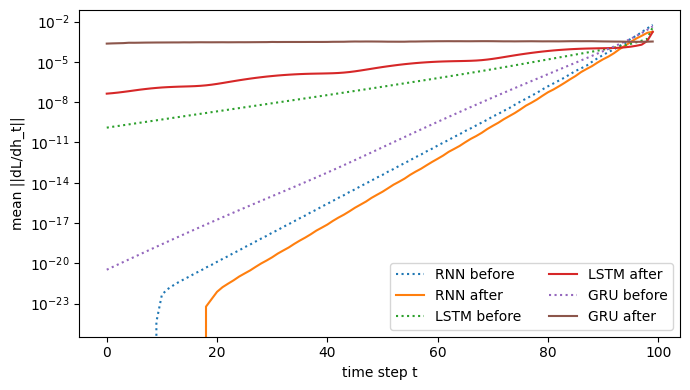

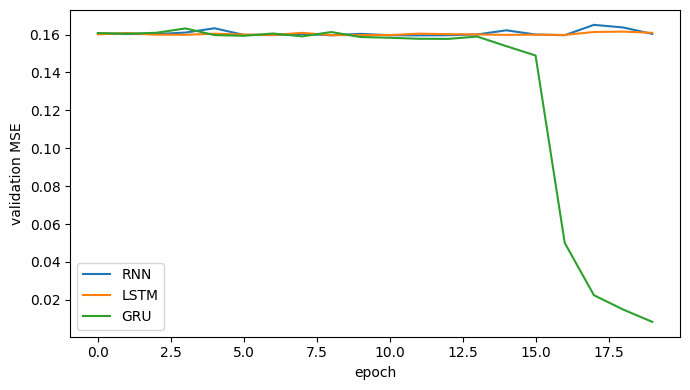

In [ ]:
# --- Gradient comparison, T=200 learning curves, and hidden-size sweep ---

# Use one fixed T=100 probe batch to compare dL/dh_t before versus after training.
gx, gy = make_adding(256, P1_GRADIENT_SEQ_LEN, 7)
tx, ty = make_adding(
    P1_ADDING_TRAIN_SIZE, P1_GRADIENT_SEQ_LEN, P1_ADDING_TRAIN_SEED
)
vx, vy = make_adding(
    P1_ADDING_VAL_SIZE, P1_GRADIENT_SEQ_LEN, P1_ADDING_VAL_SEED
)
gradient_summaries = {}
plt.figure(figsize=(7, 4))
for kind in ('RNN', 'LSTM', 'GRU'):
    set_seed(SEEDS[0])
    probe = AddingRegressor(kind, P1_HIDDEN_SIZE).to(DEVICE)
    before = gradient_norms(probe, gx, gy, DEVICE)
    probe, _, _ = train_model(
        probe, tx, ty, vx, vy, task='regression',
        epochs=P1_GRADIENT_EPOCHS, device=DEVICE,
    )
    after = gradient_norms(probe, gx, gy, DEVICE)
    # Summarize early versus late sequence signal while retaining full curves for plotting.
    gradient_summaries[kind] = {
        'before_early': float(before[:10].mean()), 'before_late': float(before[-10:].mean()),
        'after_early': float(after[:10].mean()), 'after_late': float(after[-10:].mean()),
    }
    plt.plot(np.arange(P1_GRADIENT_SEQ_LEN), before, linestyle=':', label=f'{kind} before')
    plt.plot(np.arange(P1_GRADIENT_SEQ_LEN), after, label=f'{kind} after')
plt.yscale('log'); plt.xlabel('time step t'); plt.ylabel('mean ||dL/dh_t||')
plt.legend(ncol=2); plt.tight_layout()
plt.savefig(P1_FIGURES / f'adding_gradients_T{P1_GRADIENT_SEQ_LEN}.png', dpi=160); plt.show()

# Train fresh T=200 models and plot their validation-MSE learning curves by epoch.
tx200, ty200 = make_adding(
    P1_ADDING_TRAIN_SIZE, P1_ABLATION_SEQ_LEN, P1_ADDING_TRAIN_SEED
)
vx200, vy200 = make_adding(
    P1_ADDING_VAL_SIZE, P1_ABLATION_SEQ_LEN, P1_ADDING_VAL_SEED
)
testx200, testy200 = make_adding(
    P1_ADDING_TEST_SIZE, P1_ABLATION_SEQ_LEN, P1_ADDING_TEST_SEED
)
plt.figure(figsize=(7, 4))
for kind in ('RNN', 'LSTM', 'GRU'):
    set_seed(SEEDS[0])
    probe = AddingRegressor(kind, P1_HIDDEN_SIZE).to(DEVICE)
    probe, curve, _ = train_model(
        probe, tx200, ty200, vx200, vy200, task='regression',
        epochs=P1_GRADIENT_EPOCHS, device=DEVICE,
    )
    plt.plot(curve, label=kind)
plt.xlabel('epoch'); plt.ylabel('validation MSE'); plt.legend(); plt.tight_layout()
plt.savefig(P1_FIGURES / f'adding_learning_curves_T{P1_ABLATION_SEQ_LEN}.png', dpi=160); plt.show()

# Sweep multiple widths to study capacity around the selected primary width.
for kind in ('LSTM', 'GRU'):
    for hidden in P1_HIDDEN_SWEEP:
        model_name = f'{kind}-h{hidden}'
        expected_params = sum(
            parameter.numel() for parameter in SequenceClassifier(kind, P1_HAR_CHANNELS, hidden).parameters()
        )
        for seed in SEEDS:
            if result_exists(
                'P1-HAR-hidden-sweep', model_name, seed, expected_params=expected_params
            ):
                continue
            set_seed(seed)
            data = load_har(ROOT / 'data', seed=seed)
            model = SequenceClassifier(kind, P1_HAR_CHANNELS, hidden)
            model, curve, seconds = train_model(
                model, data['x_train'], data['y_train'], data['x_val'], data['y_val'],
                task='classification', epochs=P1_SWEEP_EPOCHS, device=DEVICE,
            )
            acc, f1, _ = evaluate_classifier(model, data['x_test'], data['y_test'], DEVICE)
            append_result(RESULTS, {
                'problem': 'P1-HAR-hidden-sweep', 'model': model_name,
                'seed': seed, 'test_acc': acc, 'macro_f1': f1,
                'params': sum(parameter.numel() for parameter in model.parameters()),
                'sec_per_epoch': seconds,
                'notes': f'hidden_size={hidden};epochs={P1_SWEEP_EPOCHS};best_val_loss={min(curve):.6f}',
            })

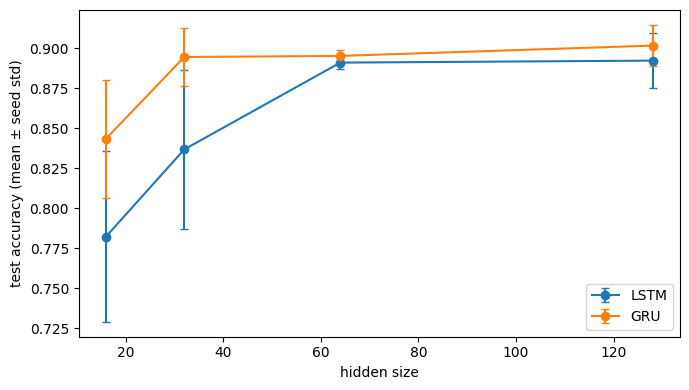

In [ ]:
# --- Validate and plot the HAR hidden-size sweep ---

# Require all LSTM/GRU hidden-size and seed combinations before summarizing.
sweep_models = tuple(
    f'{kind}-h{hidden}' for kind in ('LSTM', 'GRU') for hidden in P1_HIDDEN_SWEEP
)
sweep = validate_result_grid('P1-HAR-hidden-sweep', sweep_models, SEEDS)
# Parse architecture and width from the stable model key for grouped aggregation.
sweep[['architecture', 'hidden_size']] = sweep.model.str.extract(r'(LSTM|GRU)-h(\d+)')
sweep['hidden_size'] = sweep.hidden_size.astype(int)

# Plot mean test accuracy with seed standard deviation for each hidden size.
sweep_summary = sweep.groupby(['architecture', 'hidden_size']).test_acc.agg(['mean', 'std'])
plt.figure(figsize=(7, 4))
for kind in ('LSTM', 'GRU'):
    summary = sweep_summary.loc[kind].sort_index()
    plt.errorbar(
        summary.index, summary['mean'], yerr=summary['std'], marker='o', capsize=3,
        label=kind,
    )
plt.xlabel('hidden size'); plt.ylabel('test accuracy (mean ± seed std)')
plt.legend(); plt.tight_layout()
plt.savefig(ROOT / 'problem1' / 'figures' / 'har_hidden_size_sweep.png', dpi=160); plt.show()

In [ ]:
# --- Evidence-based Problem 1 analysis ---
from IPython.display import Markdown, display


# Validate current evidence, aggregate each study, and render the final interpretation.
def render_problem1_analysis():
    results = pd.read_csv(RESULTS)
    expected_seeds = SEEDS
    expected_models = ('RNN', 'LSTM', 'GRU')
    # Recompute parameter signatures so rows from older configurations cannot enter evidence.
    adding_expected_params = {
        kind: sum(parameter.numel() for parameter in AddingRegressor(kind, P1_HIDDEN_SIZE).parameters())
        for kind in expected_models
    }
    hidden_expected_params = {
        f'{kind}-h{hidden}': sum(
            parameter.numel() for parameter in SequenceClassifier(kind, P1_HAR_CHANNELS, hidden).parameters()
        )
        for kind in ('LSTM', 'GRU') for hidden in P1_HIDDEN_SWEEP
    }

    # Construct every exact problem/model/seed/length/parameter key required by the report.
    expected_grids = {
        'P1-HAR': [
            (model, seed, None, classifier_counts[model])
            for model in expected_models for seed in expected_seeds
        ],
        'P1-adding': [
            (model, seed, length, adding_expected_params[model])
            for model in expected_models
            for length in P1_ADDING_LENGTHS
            for seed in expected_seeds
        ],
        'P1-ablation': [
            (model, seed, P1_ABLATION_SEQ_LEN, adding_expected_params['LSTM'])
            for model in ABLATION_MODELS for seed in expected_seeds
        ],
        'P1-HAR-hidden-sweep': [
            (model, seed, None, hidden_expected_params[model])
            for model in hidden_expected_params for seed in expected_seeds
        ],
    }

    # Coerce key fields once so malformed or old string rows fail exact numeric matching.
    numeric_seed = pd.to_numeric(results['seed'], errors='coerce')
    numeric_seq_len = pd.to_numeric(results['seq_len'], errors='coerce')
    numeric_params = pd.to_numeric(results['params'], errors='coerce')
    evidence = {}
    issues = []
    for problem, expected_rows in expected_grids.items():
        matched_indices = []
        for model, seed, seq_len, params in expected_rows:
            seq_match = numeric_seq_len.isna() if seq_len is None else numeric_seq_len.eq(seq_len)
            matches = results.index[
                results['problem'].eq(problem)
                & results['model'].eq(model)
                & numeric_seed.eq(seed)
                & seq_match
                & numeric_params.eq(params)
            ].tolist()
            key = (
                f'{problem}: model={model}, seed={seed}, '
                f'seq_len={"blank" if seq_len is None else seq_len}, params={params}'
            )
            if not matches:
                issues.append(f'Missing `{key}`')
            elif len(matches) > 1:
                issues.append(f'Duplicate `{key}` ({len(matches)} rows)')
            else:
                matched_indices.extend(matches)
        evidence[problem] = results.loc[matched_indices].copy()

    # Stop before aggregation when any exact key is missing or duplicated.
    if issues:
        status = (
            '## Analysis status\n\n'
            'Current evidence is incomplete or duplicated; report aggregations were skipped.\n\n'
            + '\n'.join(f'- {issue}' for issue in issues)
        )
        display(Markdown(status))
        return

    har_evidence = evidence['P1-HAR']
    adding_evidence = evidence['P1-adding']
    ablation_evidence = evidence['P1-ablation']
    hidden_evidence = evidence['P1-HAR-hidden-sweep']

    # Aggregate HAR accuracy, cost, and timing over exactly the three required seeds.
    har_report = har_evidence.groupby('model').agg(
        acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'),
        params=('params', 'mean'), sec_per_epoch=('sec_per_epoch', 'mean'),
        seeds=('seed', 'nunique'),
    )
    har_report = har_report[har_report.seeds.eq(len(SEEDS))]
    best_har_name = har_report.acc_mean.idxmax()
    best_har = har_report.loc[best_har_name]
    har_tradeoffs = '\n'.join(
        f'- `{model}`: accuracy {row.acc_mean:.4f} ± {row.acc_std:.4f}, '
        f'{row.params:.0f} parameters, {row.sec_per_epoch:.3f} sec/epoch'
        for model, row in har_report.iterrows()
    )

    # Aggregate adding MSE by model and T against the configured solved threshold.
    adding_report = adding_evidence.groupby(['model', 'seq_len']).test_mse.agg(['mean', 'std'])
    adding_lines = []
    for model in expected_models:
        model_rows = adding_report.loc[model].sort_index()
        failures = model_rows[model_rows['mean'].ge(P1_SOLVED_MSE)]
        failure_text = (
            f'first observed mean-MSE failure at T={int(failures.index.min())}'
            if not failures.empty else f'no observed mean-MSE failure through T={max(P1_ADDING_LENGTHS)}'
        )
        trend = ', '.join(
            f'T={int(length)}: {row["mean"]:.4f} ± {row["std"]:.4f}'
            for length, row in model_rows.iterrows()
        )
        adding_lines.append(f'- `{model}`: {trend}; {failure_text}.')

    # Aggregate the matched forget-bias comparison over seeds.
    ablation_report = (
        ablation_evidence.groupby('model').test_mse.agg(['mean', 'std']).loc[list(ABLATION_MODELS)]
    )
    ablation_lines = '\n'.join(
        f'- `{model}`: test MSE {row["mean"]:.4f} ± {row["std"]:.4f}'
        for model, row in ablation_report.iterrows()
    )

    # Aggregate the multi-width sweep and identify the highest completed seed-mean accuracy.
    hidden_report = hidden_evidence.groupby('model').agg(
        acc_mean=('test_acc', 'mean'), acc_std=('test_acc', 'std'), seeds=('seed', 'nunique'),
    )
    hidden_report = hidden_report[hidden_report.seeds.eq(len(SEEDS))]
    best_hidden_name = hidden_report.acc_mean.idxmax()
    best_hidden = hidden_report.loc[best_hidden_name]

    # Use measured gradient arrays when present; otherwise explain the required early return path.
    if 'gradient_summaries' in globals():
        gradient_lines = '\n'.join(
            f'- `{model}`: before early/late {values["before_early"]:.3e}/{values["before_late"]:.3e}; '
            f'after early/late {values["after_early"]:.3e}/{values["after_late"]:.3e}'
            for model, values in gradient_summaries.items()
        )
    else:
        gradient_lines = (
            '- Measured arrays are not available in this kernel. '
            'Run the gradient cell to regenerate the per-step evidence.'
        )

    # Format one-bias, PyTorch two-bias, and classifier count formulas for the report.
    count_text = ', '.join(f'{name} {value:,}' for name, value in counts.items())
    pytorch_count_text = ', '.join(f'{name} {value:,}' for name, value in pytorch_counts.items())
    classifier_count_text = ', '.join(f'{name} {value:,}' for name, value in classifier_counts.items())
    seed_text = ', '.join(str(seed) for seed in SEEDS)

    # Assemble report sections only after all evidence preflight checks pass.
    analysis = f'''## Evidence-based interpretation

### Chosen recurrent width and parameter counts

The primary RNN/LSTM/GRU experiments use $h={P1_HIDDEN_SIZE}$. With input width {P1_HAR_CHANNELS}, the formula-derived custom one-bias cell counts are **{count_text}**. PyTorch's separately trainable input and recurrent biases give **{pytorch_count_text}** recurrent parameters. Adding the $h\to{P1_HAR_CLASSES}$ classifier gives **{classifier_count_text}** total HAR classifier parameters.

### HAR architecture tradeoff

{har_tradeoffs}

`{best_har_name}` has the highest observed three-seed mean accuracy at **{best_har.acc_mean:.4f} ± {best_har.acc_std:.4f}**. Parameter counts and measured sec/epoch above show the capacity/time tradeoff.

### Adding-task length trend

{chr(10).join(adding_lines)}

Failure is defined as seed-mean test MSE at or above the configured {P1_SOLVED_MSE} solved threshold.

### Chosen Task 5(c) LSTM forget-bias comparison

{ablation_lines}

`P1_ABLATION={P1_ABLATION!r}` selects the forget-bias 0 versus 1 comparison at T={P1_ABLATION_SEQ_LEN}, aggregated over seeds ({seed_text}).

### Hidden-size sweep

`{best_hidden_name}` has the highest completed three-seed mean test accuracy: **{best_hidden.acc_mean:.4f} ± {best_hidden.acc_std:.4f}**.

### Hidden-state gradient evidence

{gradient_lines}

Early and late values are means over the first and last ten time steps of the measured T={P1_GRADIENT_SEQ_LEN} arrays.
'''
    display(Markdown(analysis))


# Render immediately when this report cell is explicitly executed.
render_problem1_analysis()

## Evidence-based interpretation

### Chosen recurrent width and parameter counts

The primary RNN/LSTM/GRU experiments use $h=64$. With input width 9, the formula-derived custom one-bias cell counts are **RNN 4,736, LSTM 18,944, GRU 14,208**. PyTorch's separately trainable input and recurrent biases give **RNN 4,800, LSTM 19,200, GRU 14,400** recurrent parameters. Adding the $h	o6$ classifier gives **RNN 5,190, LSTM 19,590, GRU 14,790** total HAR classifier parameters.

### HAR architecture tradeoff

- `GRU`: accuracy 0.8953 ± 0.0034, 14790 parameters, 0.144 sec/epoch
- `LSTM`: accuracy 0.8911 ± 0.0041, 19590 parameters, 0.161 sec/epoch
- `RNN`: accuracy 0.7714 ± 0.0341, 5190 parameters, 0.158 sec/epoch

`GRU` has the highest observed three-seed mean accuracy at **0.8953 ± 0.0034**. Parameter counts and measured sec/epoch above show the capacity/time tradeoff.

### Adding-task length trend

- `RNN`: T=50: 0.1743 ± 0.0002, T=100: 0.1698 ± 0.0002, T=200: 0.1684 ± 0.0002, T=400: 0.1538 ± 0.0003; first observed mean-MSE failure at T=50.
- `LSTM`: T=50: 0.0679 ± 0.0875, T=100: 0.1697 ± 0.0002, T=200: 0.1686 ± 0.0001, T=400: 0.1534 ± 0.0001; first observed mean-MSE failure at T=50.
- `GRU`: T=50: 0.0042 ± 0.0010, T=100: 0.0035 ± 0.0003, T=200: 0.0084 ± 0.0021, T=400: 0.1493 ± 0.0018; first observed mean-MSE failure at T=400.

Failure is defined as seed-mean test MSE at or above the configured 0.05 solved threshold.

### Chosen Task 5(c) LSTM forget-bias comparison

- `LSTM-forget-bias-0`: test MSE 0.1686 ± 0.0002
- `LSTM-forget-bias-1`: test MSE 0.1686 ± 0.0001

`P1_ABLATION='forget_bias'` selects the forget-bias 0 versus 1 comparison at T=200, aggregated over seeds (17, 42, 2026).

### Hidden-size sweep

`GRU-h128` has the highest completed three-seed mean test accuracy: **0.9017 ± 0.0130**.

### Hidden-state gradient evidence

- `RNN`: before early/late 4.387e-26/1.253e-03; after early/late 0.000e+00/5.315e-04
- `LSTM`: before early/late 2.590e-10/5.870e-04; after early/late 7.466e-08/3.126e-04
- `GRU`: before early/late 4.813e-20/1.048e-03; after early/late 2.608e-04/3.250e-04

Early and late values are means over the first and last ten time steps of the measured T=100 arrays.
